# 02. Question-Grouped Split Design

**Question:** How can we prepare development data without placing answers to the same question in different partitions?

This notebook establishes versioned fit/development/calibration assignments, duplicate and label-conflict policies, and explicit overlap checks. No model is trained. The official UA/UQ/UD files are not read by this workflow.

Source: SciEntsBank, Dzikovska et al. (2013), https://aclanthology.org/S13-2045/. Data-derived material: CC BY-SA 3.0. Read `docs/split_design.md` for the full protocol.

In [1]:
from pathlib import Path
import subprocess
import sys
import json
import base64
import pandas as pd

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/processed/train.csv").exists()), None)
if ROOT is None:
    checkout = Path("/content/scientsbank_portfolio")
    if not checkout.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/Junghwan0516/science-answer-benchmark.git",
                        str(checkout)], check=True)
    ROOT = checkout
sys.path.insert(0, str(ROOT / "scripts"))
from build_splits import build, load_training, verify_split
print("Split source: official training CSV only")

Split source: official training CSV only


## 1. Freeze the allocation rule

Sort the 135 question IDs, permute with NumPy PCG64 seed 42, and allocate 95/20/20 whole questions. Accept the first candidate with at least 10 records of each label in fit, at least 3 in each held-out partition, and 12–18% of answer records in each held-out partition. Stop after at most 1,000 candidates.

This constrained allocation uses only training IDs, counts, and labels. It does not search model scores or official test labels. A support of three is a coverage minimum, not a reliable sample size.

In [2]:
protocol = build(ROOT)
print("\nProtocol version:", protocol["version"])
print("Source SHA-256:", protocol["source_training_sha256"])

                answer_count  question_count  unique_inputs  conflicting_rows  answer_percentage  question_percentage
internal_split                                                                                                       
fit                     3536              95           3438                15          71.161199            70.370370
development              715              20            702                 0          14.389213            14.814815
calibration              718              20            686                 0          14.449587            14.814815

Class support:
label           correct  partially_correct_incomplete  irrelevant  contradictory  non_domain
internal_split                                                                              
fit                1419                           964         753            383          17
development         314                           148         176             74           3
calibration         27

## 2. Check question and class supports

The first eligible candidate is candidate 5. Fit has 3,536 records, development 715, and calibration 718. Every question belongs to exactly one partition. The rare-class counts are 17/3/3; their uncertainty must remain visible in later model reports.

In [3]:
summary = pd.read_csv(ROOT / "reports/splits/partition_summary.csv")
support = pd.read_csv(ROOT / "reports/splits/class_support.csv")
print(summary.to_string(index=False))
print("\nClass supports:")
print(support.to_string(index=False))

internal_split  answer_count  question_count  unique_inputs  conflicting_rows  answer_percentage  question_percentage
           fit          3536              95           3438                15          71.161199            70.370370
   development           715              20            702                 0          14.389213            14.814815
   calibration           718              20            686                 0          14.449587            14.814815

Class supports:
internal_split  correct  partially_correct_incomplete  irrelevant  contradictory  non_domain
           fit     1419                           964         753            383          17
   development      314                           148         176             74           3
   calibration      275                           212         186             42           3


## 3. Inspect the partition figures

Answer proportions differ from question proportions because questions contain unequal numbers of answers. Domain coverage is reported after allocation, not optimized. All three plots are computed from training-only assignments.

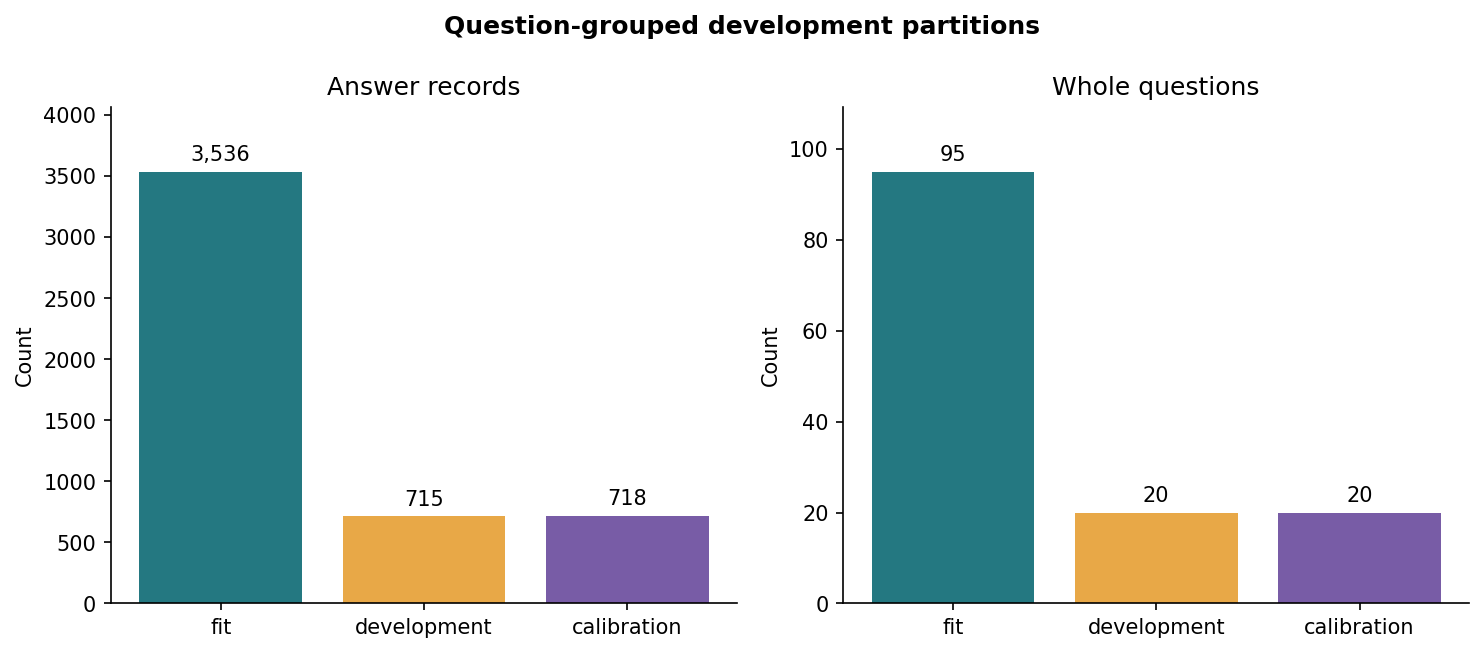

In [4]:
image_path = ROOT / "reports/splits/figures/01_partition_sizes.png"
display({"image/png": base64.b64encode(image_path.read_bytes()).decode("ascii")}, raw=True)

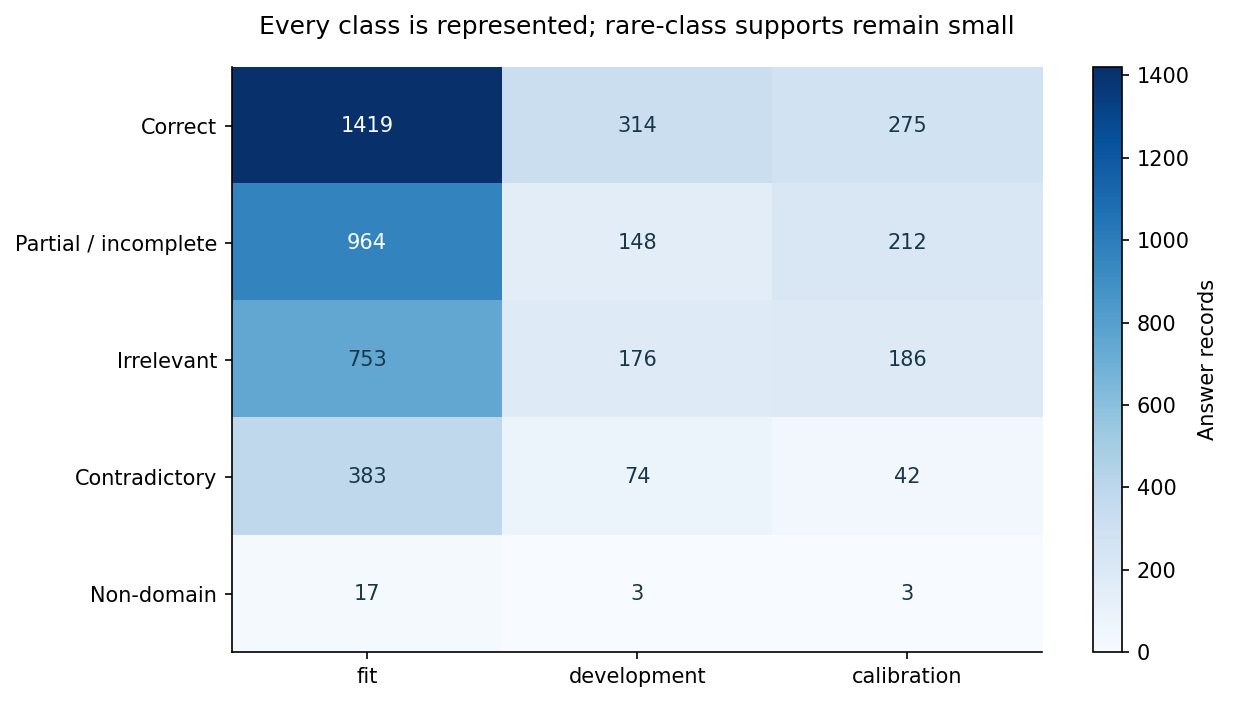

In [5]:
image_path = ROOT / "reports/splits/figures/02_class_support.png"
display({"image/png": base64.b64encode(image_path.read_bytes()).decode("ascii")}, raw=True)

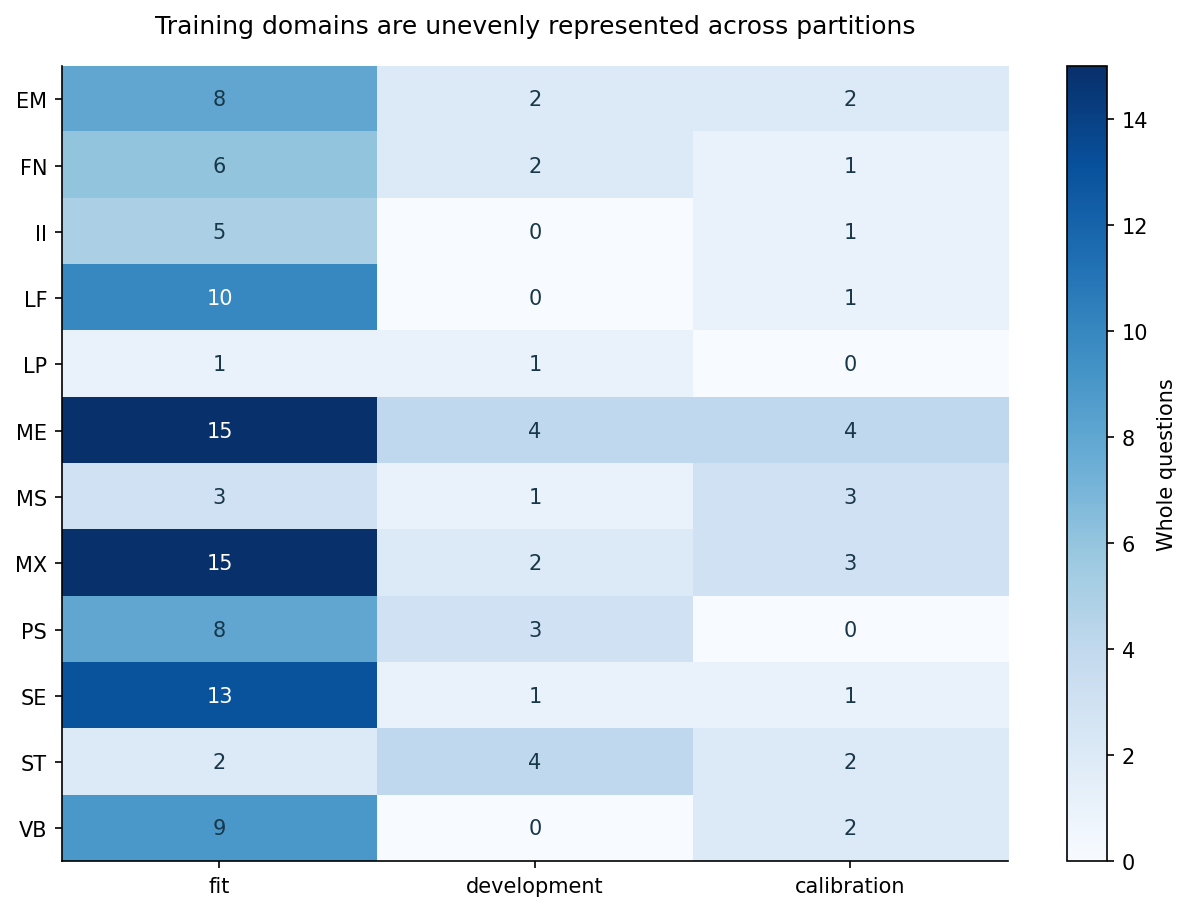

In [6]:
image_path = ROOT / "reports/splits/figures/03_domain_question_support.png"
display({"image/png": base64.b64encode(image_path.read_bytes()).decode("ascii")}, raw=True)

## 4. Verify disjointness and preserve annotations

The checks cover answer IDs, question IDs, and normalized complete inputs. They do not establish learner-disjointness or detect all paraphrases. Original rows and labels remain unchanged. Primary sample weights are one. Optional inverse-input-multiplicity weights are prepared for fit-only sensitivity experiments; no weighting experiment is run here.

In [7]:
verify_split(ROOT)
print(pd.read_csv(ROOT / "reports/splits/overlap_checks.csv").to_string(index=False))
assignments = pd.read_csv(ROOT / "data/splits/v1/answer_assignments.csv")
print("\nFlagged conflicting rows by partition:")
print(assignments.groupby("internal_split")["has_conflicting_labels"].sum().to_string())

PASS: complete coverage, unchanged labels, reproducible assignments, zero question/input overlap, versioned hashes, and training-only split generation.
 left_split right_split  shared_sample_ids  shared_question_ids  shared_normalized_inputs
        fit development                  0                    0                         0
        fit calibration                  0                    0                         0
development calibration                  0                    0                         0

Flagged conflicting rows by partition:
internal_split
calibration     0
development     0
fit            15


## 5. Join the manifest to the source data

Use a one-to-one join on sample_id. Assignment tables do not duplicate answer text. Downstream vectorizers, scalers, and model parameters must be learned from fit only. Development selects classifier settings; calibration is reserved for the selected model's probabilities and review threshold.

In [8]:
training = load_training(ROOT)
joined = training.merge(assignments[["sample_id", "internal_split"]], on="sample_id", validate="one_to_one")
assert len(joined) == 4969
print(joined[["sample_id", "question_id", "label", "internal_split"]].head(8).to_string(index=False))

         sample_id question_id      label internal_split
train:EM.45b.110.1      EM_45b irrelevant    development
train:EM.45b.113.1      EM_45b    correct    development
train:EM.45b.114.1      EM_45b    correct    development
train:EM.45b.261.1      EM_45b irrelevant    development
train:EM.45b.383.1      EM_45b irrelevant    development
train:EM.45b.384.1      EM_45b    correct    development
train:EM.45b.385.1      EM_45b irrelevant    development
train:EM.45b.395.1      EM_45b    correct    development


## 6. Final evaluation is still a separate design decision

This split is for development. A model fitted only on 95 question IDs has not seen every question appearing in the official UA partition. Before any official scoring, freeze the final-fit procedure: either document a full-training refit with cross-fitted calibration, or retain the held-out setup and report the actual seen-question/held-out-question slices within official UA.

Do not refit on calibration labels while presenting those same predictions as independent calibration. No official UA/UQ/UD scores, fitted model, classifier hyperparameters, or production accuracy are produced by this notebook.

**Next task:** implement classical baselines in `03_classical_baselines.ipynb` using these immutable assignments. Consider fixed-five-class macro-F1 with class supports, alongside accuracy, weighted-F1, and the confusion matrix. The tiny minority support limits model-selection certainty.